# 09 — Final Results Consolidation and Publication-Quality Figures

## Objective

This notebook consolidates the results from the Caco-2 permeability research and prepares the numerical summaries and figures required for scientific interpretation and manuscript preparation.

The study investigates how molecular representation influences the relationship between chemical-space distance and prediction error.

Three molecular representations were investigated:

1. Morgan fingerprints
2. RDKit molecular descriptors
3. Hybrid representation

The study includes:

- Random Forest baseline analysis
- XGBoost and LightGBM robustness analyses
- Chemical-space distance and prediction-error correlations
- Distance-quintile analysis
- Statistical comparisons between distance groups
- Scaffold-based generalization analysis

## Primary Research Question

Does molecular representation influence how chemical-space distance relates to prediction error in Caco-2 permeability prediction?

## Planned Workflow

1. Consolidate model performance metrics.
2. Compare distance-error correlations across algorithms.
3. Summarize distance-quintile results.
4. Compare random-split and scaffold-split performance.
5. Generate publication-quality figures.
6. Prepare consistent result tables for the manuscript.
7. Identify remaining validation requirements and limitations.

This notebook focuses on reproducibility, clear presentation, and scientific interpretation rather than introducing additional predictive models.

# Load the saved results

In [1]:
import pandas as pd
import os

files = [
    "scaffold_split_predictions.csv",
    "scaffold_distance_error_correlations.csv",
    "scaffold_distance_quintile_analysis.csv",
    "scaffold_split_model_performance.csv"
]

for file in files:
    print(f"{file}: {'Found' if os.path.exists(file) else 'MISSING'}")

scaffold_split_predictions.csv: Found
scaffold_distance_error_correlations.csv: Found
scaffold_distance_quintile_analysis.csv: Found
scaffold_split_model_performance.csv: Found


In [2]:
import pandas as pd

scaffold_predictions = pd.read_csv("scaffold_split_predictions.csv")
scaffold_correlations = pd.read_csv("scaffold_distance_error_correlations.csv")
scaffold_quintiles = pd.read_csv("scaffold_distance_quintile_analysis.csv")
scaffold_performance = pd.read_csv("scaffold_split_model_performance.csv")

print("Scaffold predictions:", scaffold_predictions.shape)
print("Distance-error correlations:", scaffold_correlations.shape)
print("Distance quintile analysis:", scaffold_quintiles.shape)
print("Scaffold model performance:", scaffold_performance.shape)

Scaffold predictions: (4247, 10)
Distance-error correlations: (3, 3)
Distance quintile analysis: (3, 8)
Scaffold model performance: (3, 4)


# Inspect the results

In [3]:
print("=== SCAFFOLD MODEL PERFORMANCE ===")
display(scaffold_performance)

print("=== DISTANCE–ERROR CORRELATIONS ===")
display(scaffold_correlations)

print("=== DISTANCE QUINTILE ANALYSIS ===")
display(scaffold_quintiles)

print("=== SCAFFOLD PREDICTIONS ===")
display(scaffold_predictions.head())

=== SCAFFOLD MODEL PERFORMANCE ===


,Representation,MAE,RMSE,R2
0,Morgan,0.4503,0.6257,0.4495
1,RDKit,0.4567,0.6203,0.4590
2,Hybrid,0.4513,0.6157,0.4670


=== DISTANCE–ERROR CORRELATIONS ===


,Representation,Spearman_rho,p_value
0,Morgan,0.093129,1.197487e-09
1,RDKit,0.140185,4.376612e-20
2,Hybrid,0.099445,8.307966e-11


=== DISTANCE QUINTILE ANALYSIS ===


,Representation,Q1_mean_error,Q5_mean_error,Increase_percent,U_statistic,p_value,p_holm,significant_after_holm
0,Morgan,0.425239,0.503847,18.485658,307174.0,1.683328e-07,3.366656e-07,True
1,RDKit,0.390203,0.533349,36.684887,289124.0,1.025603e-12,3.076809e-12,True
2,Hybrid,0.426442,0.509119,19.387548,309103.0,2.566026e-07,3.366656e-07,True


=== SCAFFOLD PREDICTIONS ===


,canonical_smiles,scaffold,log10_median_papp,y_true,Morgan_pred,Morgan_error,RDKit_pred,RDKit_error,Hybrid_pred,Hybrid_error
0,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1,c1ccc(-c2nc3ccccn3n2)cc1,0.542825,0.542825,1.208765,0.665940,1.187154,0.644328,1.201493,0.658668
1,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,c1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,1.491362,1.491362,1.276727,0.214634,1.249238,0.242124,1.181594,0.309768
2,Brc1ccc2[nH]nc(C3=CCCNC3)c2c1,C1=C(c2n[nH]c3ccccc23)CNCC1,0.897627,0.897627,1.007112,0.109485,0.995471,0.097844,1.011336,0.113709
3,C#CCN(C)CCc1nnn(-c2ccccc2)c1CC,c1ccc(-n2ccnn2)cc1,1.230449,1.230449,1.195823,0.034626,1.121701,0.108748,1.043828,0.186621
4,C#CCN(C)CCc1nnn(-c2ccccc2)c1CCC,c1ccc(-n2ccnn2)cc1,1.235528,1.235528,1.197651,0.037878,1.188944,0.046584,1.058430,0.177098


# Consolidate model performance

In [4]:
# Random-split results from Notebooks 06–07
random_performance = pd.DataFrame([
    ["RF",       "Morgan", 0.3842, 0.5483, 0.5571],
    ["RF",       "RDKit",  0.4037, 0.5670, 0.5263],
    ["RF",       "Hybrid", 0.3974, 0.5584, 0.5405],

    ["XGBoost",  "Morgan", 0.4546, 0.6054, 0.4600],
    ["XGBoost",  "RDKit",  0.4256, 0.5775, 0.5086],
    ["XGBoost",  "Hybrid", 0.4377, 0.5861, 0.4939],

    ["LightGBM", "Morgan", 0.4655, 0.6240, 0.4262],
    ["LightGBM", "RDKit",  0.4421, 0.5974, 0.4741],
    ["LightGBM", "Hybrid", 0.4444, 0.5972, 0.4745],
], columns=["Model", "Representation", "MAE", "RMSE", "R2"])

random_performance["Split"] = "Random"

# Scaffold-split results from Notebook 08
scaffold_performance = scaffold_performance.copy()
scaffold_performance["Model"] = "RF"
scaffold_performance["Split"] = "Scaffold"

# Standardize column order
scaffold_performance = scaffold_performance[
    ["Model", "Representation", "MAE", "RMSE", "R2", "Split"]
]

random_performance = random_performance[
    ["Model", "Representation", "MAE", "RMSE", "R2", "Split"]
]

# Combine results
all_performance = pd.concat(
    [random_performance, scaffold_performance],
    ignore_index=True
)

display(all_performance.round(4))

,Model,Representation,MAE,RMSE,R2,Split
0,RF,Morgan,0.3842,0.5483,0.5571,Random
1,RF,RDKit,0.4037,0.5670,0.5263,Random
2,RF,Hybrid,0.3974,0.5584,0.5405,Random
3,XGBoost,Morgan,0.4546,0.6054,0.4600,Random
4,XGBoost,RDKit,0.4256,0.5775,0.5086,Random
5,XGBoost,Hybrid,0.4377,0.5861,0.4939,Random
6,LightGBM,Morgan,0.4655,0.6240,0.4262,Random
7,LightGBM,RDKit,0.4421,0.5974,0.4741,Random
8,LightGBM,Hybrid,0.4444,0.5972,0.4745,Random
9,RF,Morgan,0.4503,0.6257,0.4495,Scaffold


# Save the consolidated table

In [5]:
all_performance.to_csv(
    "consolidated_model_performance.csv",
    index=False
)

print("Saved:", "consolidated_model_performance.csv")
print("Total rows:", len(all_performance))

Saved: consolidated_model_performance.csv
Total rows: 12


# Generate Figure 1

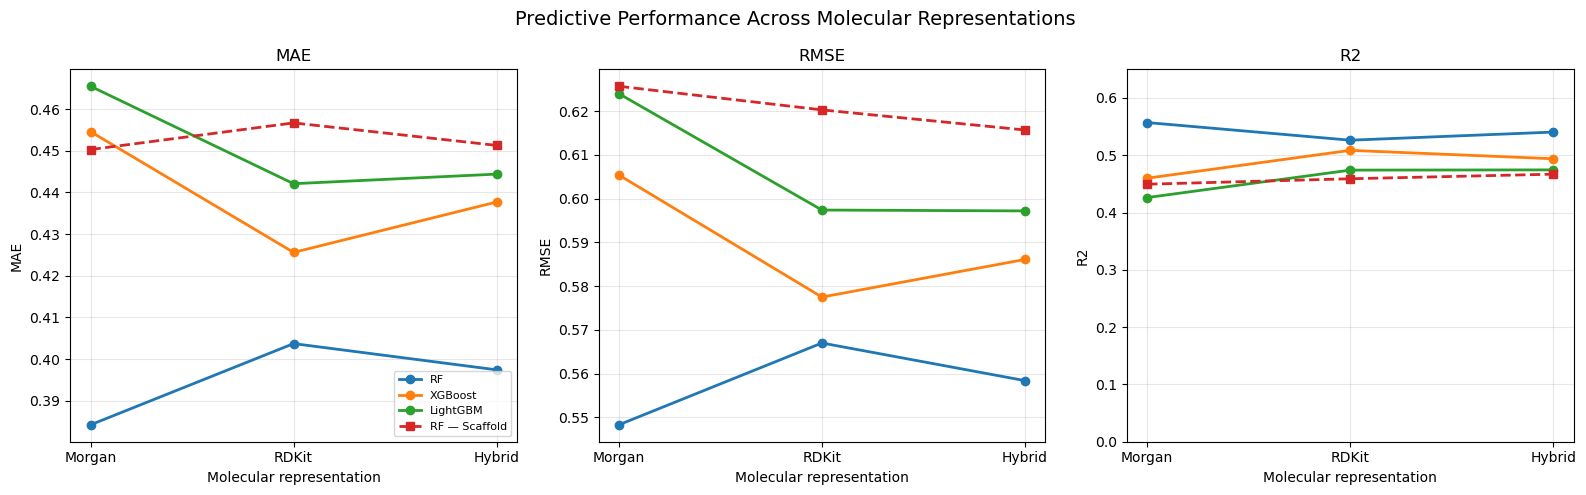

In [6]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["MAE", "RMSE", "R2"]
representations = ["Morgan", "RDKit", "Hybrid"]
models = ["RF", "XGBoost", "LightGBM"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, metrics):
    random_data = all_performance[
        all_performance["Split"] == "Random"
    ]

    for model in models:
        subset = random_data[random_data["Model"] == model]
        subset = subset.set_index("Representation").reindex(representations)

        ax.plot(
            representations,
            subset[metric],
            marker="o",
            linewidth=2,
            label=model
        )

    # Add scaffold-split RF results as dashed lines
    scaffold_data = all_performance[
        all_performance["Split"] == "Scaffold"
    ].set_index("Representation").reindex(representations)

    ax.plot(
        representations,
        scaffold_data[metric],
        marker="s",
        linestyle="--",
        linewidth=2,
        label="RF — Scaffold"
    )

    ax.set_title(metric)
    ax.set_xlabel("Molecular representation")
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3)

    if metric == "R2":
        ax.set_ylim(0, 0.65)

axes[0].legend(fontsize=8)
fig.suptitle("Predictive Performance Across Molecular Representations", fontsize=14)
plt.tight_layout()

plt.savefig(
    "Figure1_model_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 1A — Random-split performance

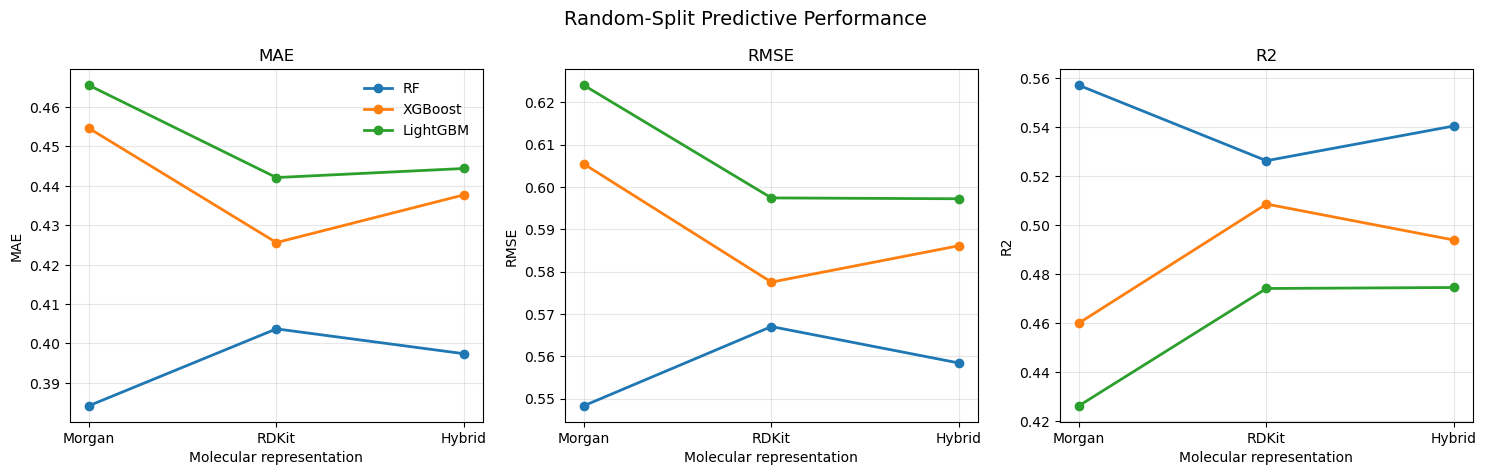

In [7]:
import matplotlib.pyplot as plt

random_data = all_performance[
    all_performance["Split"] == "Random"
]

metrics = ["MAE", "RMSE", "R2"]
representations = ["Morgan", "RDKit", "Hybrid"]
models = ["RF", "XGBoost", "LightGBM"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

for ax, metric in zip(axes, metrics):
    for model in models:
        subset = random_data[
            random_data["Model"] == model
        ].set_index("Representation").reindex(representations)

        ax.plot(
            representations,
            subset[metric],
            marker="o",
            linewidth=2,
            label=model
        )

    ax.set_title(metric)
    ax.set_xlabel("Molecular representation")
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3)

axes[0].legend(frameon=False)
fig.suptitle("Random-Split Predictive Performance", fontsize=14)
plt.tight_layout()

plt.savefig("Figure1A_random_split_performance.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Figure 1B — Scaffold-split performance

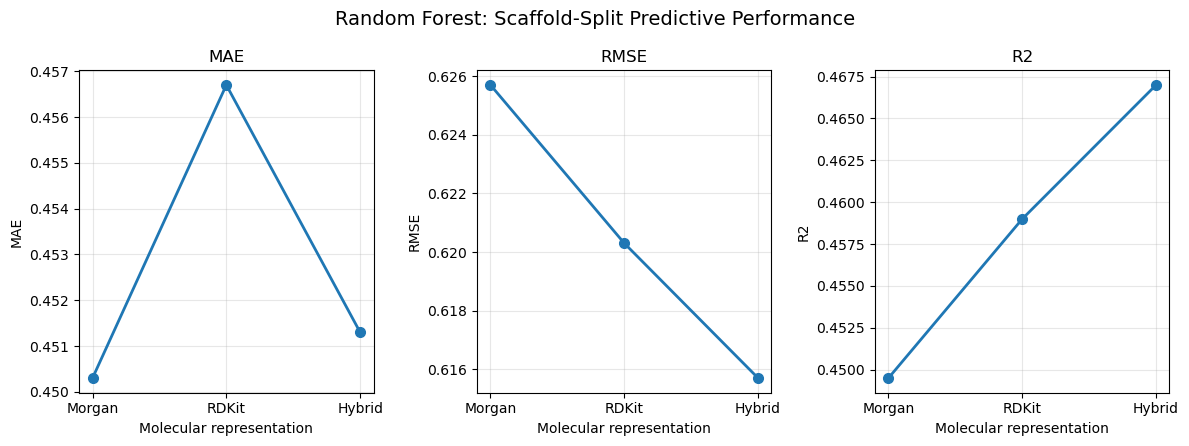

In [9]:
# Figure 1B — Scaffold-split performance
import matplotlib.pyplot as plt

scaffold_data = all_performance[
    all_performance["Split"] == "Scaffold"
]

metrics = ["MAE", "RMSE", "R2"]
representations = ["Morgan", "RDKit", "Hybrid"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

for ax, metric in zip(axes, metrics):
    subset = (
        scaffold_data
        .set_index("Representation")
        .reindex(representations)
    )

    ax.plot(
        representations,
        subset[metric],
        marker="o",
        linewidth=2,
        markersize=7,
        label="RF — Scaffold split"
    )

    ax.set_title(metric)
    ax.set_xlabel("Molecular representation")
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Random Forest: Scaffold-Split Predictive Performance",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "Figure1B_scaffold_split_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
import os

files = [
    "Figure1A_random_split_performance.png",
    "Figure1B_scaffold_split_performance.png",
    "consolidated_model_performance.csv"
]

for file in files:
    print(file, "—", "Saved" if os.path.exists(file) else "Missing")

Figure1A_random_split_performance.png — Saved
Figure1B_scaffold_split_performance.png — Saved
consolidated_model_performance.csv — Saved


# Figure 2 — Chemical-Space Distance vs Prediction Error

# Load the random-split correlation results

In [11]:
import os

for file in os.listdir("."):
    if "correlation" in file.lower() or "distance" in file.lower():
        print(file)

scaffold_distance_error_correlations.csv
scaffold_distance_quintile_analysis.csv


# Create the consolidated correlation table

In [12]:
# Random-split RF correlations from Notebook 06
random_correlations = pd.DataFrame([
    ["Morgan", 0.177002, 3.877930e-30],
    ["RDKit",  0.250541, 1.407923e-59],
    ["Hybrid", 0.188698, 4.295097e-34]
], columns=["Representation", "Spearman_rho", "p_value"])

random_correlations["Split"] = "Random"

# Scaffold-split RF correlations loaded from Notebook 08
scaffold_correlations = scaffold_correlations.copy()
scaffold_correlations["Split"] = "Scaffold"

# Combine the two evaluation settings
all_correlations = pd.concat(
    [random_correlations, scaffold_correlations],
    ignore_index=True
)

display(
    all_correlations[
        ["Split", "Representation", "Spearman_rho", "p_value"]
    ].round(6)
)

,Split,Representation,Spearman_rho,p_value
0,Random,Morgan,0.177002,0.0
1,Random,RDKit,0.250541,0.0
2,Random,Hybrid,0.188698,0.0
3,Scaffold,Morgan,0.093129,0.0
4,Scaffold,RDKit,0.140185,0.0
5,Scaffold,Hybrid,0.099445,0.0


# Create Figure 2 — Distance–error correlations
This figure compares Spearman's correlation between chemical-space distance and prediction error for the two split strategies.

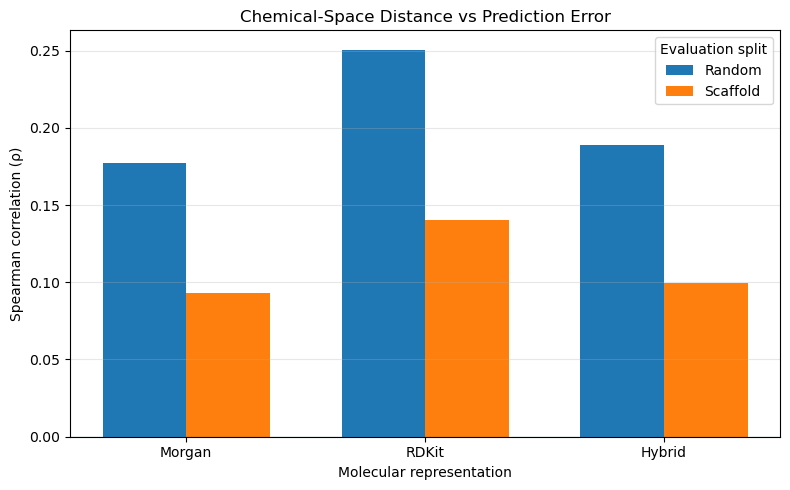

In [13]:
import matplotlib.pyplot as plt
import numpy as np

representations = ["Morgan", "RDKit", "Hybrid"]
splits = ["Random", "Scaffold"]

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(representations))
width = 0.35

for i, split in enumerate(splits):
    subset = (
        all_correlations[all_correlations["Split"] == split]
        .set_index("Representation")
        .reindex(representations)
    )

    ax.bar(
        x + (i - 0.5) * width,
        subset["Spearman_rho"],
        width,
        label=split
    )

ax.set_xticks(x)
ax.set_xticklabels(representations)
ax.set_xlabel("Molecular representation")
ax.set_ylabel("Spearman correlation (ρ)")
ax.set_title("Chemical-Space Distance vs Prediction Error")
ax.axhline(0, linewidth=0.8)
ax.legend(title="Evaluation split")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("Figure2_distance_error_correlations.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Save the correlation results

In [14]:
all_correlations.to_csv(
    "consolidated_distance_error_correlations.csv",
    index=False
)

print("Correlation table saved.")
print("Figure 2 saved:", 
      os.path.exists("Figure2_distance_error_correlations.png"))

Correlation table saved.
Figure 2 saved: True


# Figure 3 — Prediction error across distance quintiles

This figure will show how mean absolute error changes across five distance groups, from Q1 (nearest molecules) to Q5 (most distant molecules).

In [15]:
for file in os.listdir("."):
    if "quintile" in file.lower() or "distance" in file.lower():
        print(file)

consolidated_distance_error_correlations.csv
Figure2_distance_error_correlations.png
scaffold_distance_error_correlations.csv
scaffold_distance_quintile_analysis.csv


# Check the available quintile variables

In [16]:
for name in dir():
    if "quintile" in name.lower() or "q1q5" in name.lower():
        print(name)

scaffold_quintiles


In [17]:
for name in dir():
    if any(term in name.lower() for term in [
        "quintile", "q1q5", "bin_error", "distance_error"
    ]):
        print(name)

scaffold_quintiles


In [18]:
import os

for file in os.listdir("."):
    if any(term in file.lower() for term in [
        "prediction", "random", "rf", "result"
    ]):
        print(file)

06_Baseline Prediction Model.ipynb
09_Final Results Consolidation and Publication-Quality Figures.ipynb
Caco2_chemical_space_primary_results.pkl
consolidated_model_performance.csv
Figure1A_random_split_performance.png
Figure1B_scaffold_split_performance.png
Figure1_model_performance.png
scaffold_split_model_performance.csv
scaffold_split_predictions.csv


# Inspect the saved primary results

In [19]:
import pickle

with open("Caco2_chemical_space_primary_results.pkl", "rb") as f:
    primary_results = pickle.load(f)

print("Object type:", type(primary_results))

if isinstance(primary_results, dict):
    print("Available keys:")
    for key in primary_results.keys():
        print("-", key)
elif hasattr(primary_results, "columns"):
    print("Columns:", primary_results.columns.tolist())
    display(primary_results.head())

Object type: <class 'dict'>
Available keys:
- n_molecules
- n_test_molecules
- Morgan_features
- RDKit_features
- Hybrid_features
- model_performance
- distance_error_spearman
- q1_q5
- friedman_test
- pairwise_wilcoxon
- standardized_slopes
- bootstrap_slope_comparison
- outlier_robustness


# Inspect the saved Q1–Q5 results

In [20]:
print("Q1–Q5 result type:", type(primary_results["q1_q5"]))

print("\nSaved Q1–Q5 results:")
display(primary_results["q1_q5"])

Q1–Q5 result type: <class 'dict'>

Saved Q1–Q5 results:


{'Morgan': {'Q1_mean_error': 0.3249,
  'Q5_mean_error': 0.4878,
  'increase_percent': 50.1,
  'rank_biserial': 0.2876,
  'p': 6.271338e-24},
 'RDKit': {'Q1_mean_error': 0.2964,
  'Q5_mean_error': 0.5351,
  'increase_percent': 80.6,
  'rank_biserial': 0.3549,
  'p': 1.854186e-35},
 'Hybrid': {'Q1_mean_error': 0.318,
  'Q5_mean_error': 0.5014,
  'increase_percent': 57.7,
  'rank_biserial': 0.274,
  'p': 8.430179e-22}}

# Create an endpoint comparison table

In [21]:
# Random-split Q1 and Q5 results recovered from the saved primary results
random_q1q5 = pd.DataFrame([
    ["Morgan", 0.3249, 0.4878, 50.1],
    ["RDKit",  0.2964, 0.5351, 80.6],
    ["Hybrid", 0.3180, 0.5014, 57.7],
], columns=[
    "Representation", "Q1_mean_error",
    "Q5_mean_error", "Increase_percent"
])

random_q1q5["Split"] = "Random"

# Scaffold-split endpoint results from the saved CSV
scaffold_q1q5 = scaffold_quintiles[
    ["Representation", "Q1_mean_error",
     "Q5_mean_error", "Increase_percent"]
].copy()

scaffold_q1q5["Split"] = "Scaffold"

all_q1q5 = pd.concat(
    [random_q1q5, scaffold_q1q5],
    ignore_index=True
)

display(all_q1q5.round(4))

,Representation,Q1_mean_error,Q5_mean_error,Increase_percent,Split
0,Morgan,0.3249,0.4878,50.1000,Random
1,RDKit,0.2964,0.5351,80.6000,Random
2,Hybrid,0.3180,0.5014,57.7000,Random
3,Morgan,0.4252,0.5038,18.4857,Scaffold
4,RDKit,0.3902,0.5333,36.6849,Scaffold
5,Hybrid,0.4264,0.5091,19.3875,Scaffold


# Save the consolidated table

In [22]:
all_q1q5.to_csv(
    "consolidated_distance_quintile_endpoints.csv",
    index=False
)

print("Saved:", "consolidated_distance_quintile_endpoints.csv")
print("Total rows:", len(all_q1q5))

Saved: consolidated_distance_quintile_endpoints.csv
Total rows: 6


# Create Figure 3 — Q1 vs Q5 prediction error

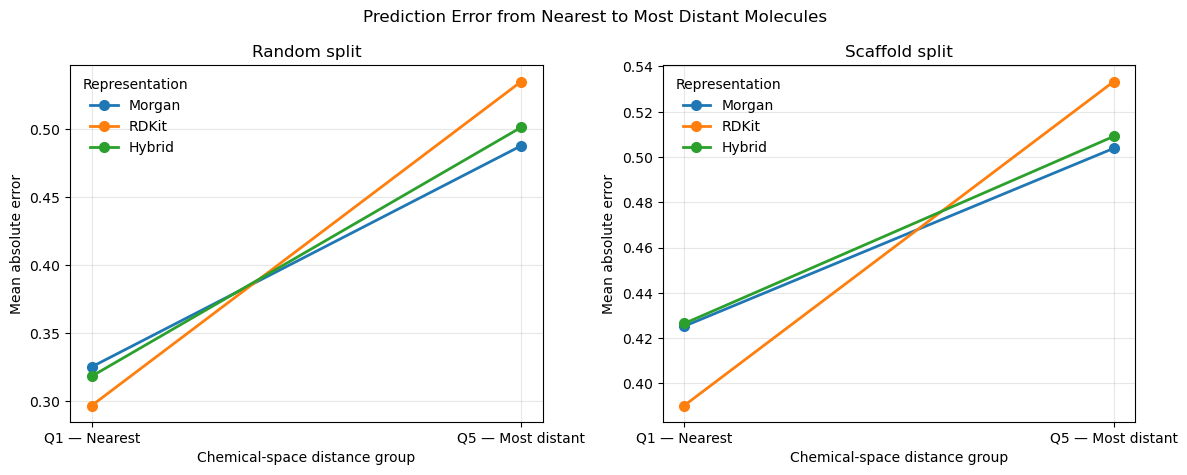

In [24]:
import matplotlib.pyplot as plt

representations = ["Morgan", "RDKit", "Hybrid"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for ax, split in zip(axes, ["Random", "Scaffold"]):
    subset = (
        all_q1q5[all_q1q5["Split"] == split]
        .set_index("Representation")
        .reindex(representations)
    )

    for rep in representations:
        row = subset.loc[rep]

        ax.plot(
            ["Q1 — Nearest", "Q5 — Most distant"],
            [row["Q1_mean_error"], row["Q5_mean_error"]],
            marker="o",
            linewidth=2,
            markersize=7,
            label=rep
        )

    ax.set_title(f"{split} split")
    ax.set_xlabel("Chemical-space distance group")
    ax.set_ylabel("Mean absolute error")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Representation", frameon=False)

fig.suptitle("Prediction Error from Nearest to Most Distant Molecules")
plt.tight_layout()

plt.savefig(
    "Figure3_Q1_Q5_error_lineplot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save and verify Figure 3

In [25]:
import os

print(
    "Figure 3 saved:",
    os.path.exists("Figure3_Q1_Q5_error_lineplot.png")
)

print(
    "Quintile table saved:",
    os.path.exists("consolidated_distance_quintile_endpoints.csv")
)

Figure 3 saved: True
Quintile table saved: True


# Generate Figure 4

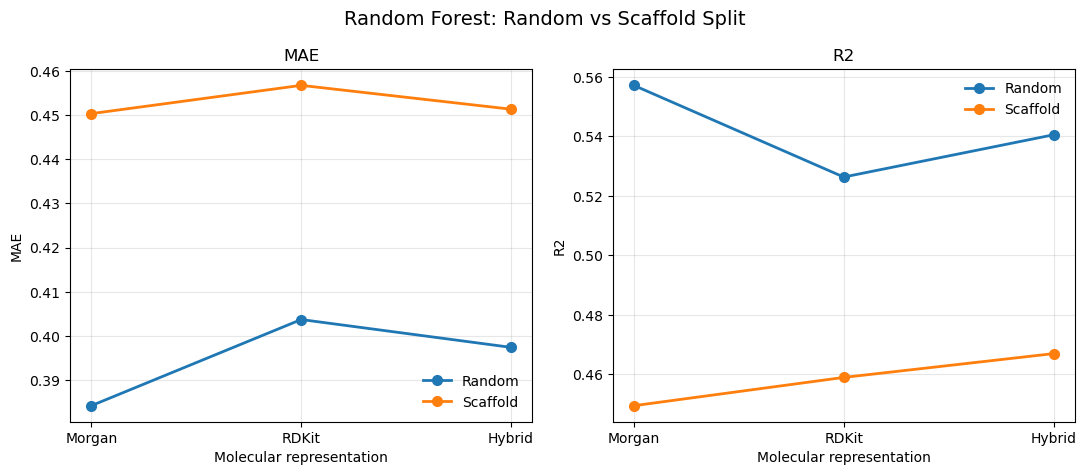

In [27]:
import matplotlib.pyplot as plt

rf_data = all_performance[
    all_performance["Model"] == "RF"
]

representations = ["Morgan", "RDKit", "Hybrid"]
splits = ["Random", "Scaffold"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

for ax, metric in zip(axes, ["MAE", "R2"]):
    for split in splits:
        subset = (
            rf_data[rf_data["Split"] == split]
            .set_index("Representation")
            .reindex(representations)
        )

        ax.plot(
            representations,
            subset[metric],
            marker="o",
            linewidth=2,
            markersize=7,
            label=split
        )

    ax.set_xlabel("Molecular representation")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.grid(True, alpha=0.3)
    ax.legend(frameon=False)

fig.suptitle(
    "Random Forest: Random vs Scaffold Split",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "Figure4_random_vs_scaffold_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save and verify Figure 4

In [28]:
import os

print(
    "Figure 4 saved:",
    os.path.exists("Figure4_random_vs_scaffold_performance.png")
)

Figure 4 saved: True


# Verify all figures and tables

In [29]:
import os

expected_files = [
    "Figure1A_random_split_performance.png",
    "Figure1B_scaffold_split_performance.png",
    "Figure2_distance_error_correlations.png",
    "Figure3_Q1_Q5_error_lineplot.png",
    "Figure4_random_vs_scaffold_performance.png",
    "consolidated_model_performance.csv",
    "consolidated_distance_error_correlations.csv",
    "consolidated_distance_quintile_endpoints.csv"
]

for file in expected_files:
    status = "Saved" if os.path.exists(file) else "MISSING"
    print(f"{file}: {status}")

Figure1A_random_split_performance.png: Saved
Figure1B_scaffold_split_performance.png: Saved
Figure2_distance_error_correlations.png: Saved
Figure3_Q1_Q5_error_lineplot.png: Saved
Figure4_random_vs_scaffold_performance.png: Saved
consolidated_model_performance.csv: Saved
consolidated_distance_error_correlations.csv: Saved
consolidated_distance_quintile_endpoints.csv: Saved


# Final Results Consolidation — Summary and Interpretation

## 1. Objective

This notebook consolidates predictive performance, chemical-space distance–error correlations, distance-quintile endpoint comparisons, and scaffold-based generalization results for Caco-2 permeability prediction.

The central research question is whether molecular representation influences the relationship between chemical-space distance and prediction error.

## 2. Predictive Performance

Random Forest, XGBoost, and LightGBM were evaluated using a random train–test split with Morgan fingerprints, RDKit descriptors, and a hybrid representation.

Random Forest was additionally evaluated using a scaffold split to assess generalization to molecules with scaffolds absent from the training set.

The random-split results showed that Random Forest with Morgan fingerprints achieved the lowest MAE (0.3842) and RMSE (0.5483), as well as the highest R² (0.5571), among the nine random-split model–representation configurations.

Under scaffold splitting, the hybrid representation achieved the highest R² (0.4670) and lowest RMSE (0.6157), while Morgan fingerprints achieved the lowest MAE (0.4503).

## 3. Chemical-Space Distance and Prediction Error

Spearman correlations between chemical-space distance and absolute prediction error were positive for all three representations under both evaluation strategies.

RDKit descriptors had the highest observed correlation under the random split (ρ = 0.2505) and scaffold split (ρ = 0.1402).

The correlations were weaker under scaffold splitting than under random splitting for all representations.

These associations are relatively weak and do not establish that chemical-space distance alone determines prediction error. Differences between correlation coefficients should not be described as statistically significant without an appropriate comparison test.

## 4. Distance-Quintile Endpoint Comparison

Mean absolute error was higher in Q5 than in Q1 for all representations under both evaluation strategies.

The random-split Q1-to-Q5 error increases were:
- Morgan: 50.1%
- RDKit: 80.6%
- Hybrid: 57.7%

The scaffold-split Q1-to-Q5 error increases were:
- Morgan: 18.49%
- RDKit: 36.68%
- Hybrid: 19.39%

The consolidated Figure 3 compares the observed Q1 and Q5 endpoints only. It does not display the intermediate quintiles.

## 5. Random Split versus Scaffold Split

For Random Forest, scaffold-split performance was lower than random-split performance across all three representations in terms of R², with higher MAE.

This supports the importance of evaluating molecular models on scaffold-separated test data when investigating generalization to structurally distinct compounds.

The magnitude of performance changes differs by representation. These comparisons are descriptive and should not be interpreted as proof that one representation is statistically superior.

## 6. Figures and Saved Tables

- Figure 1A: Random-split predictive performance
- Figure 1B: Scaffold-split predictive performance
- Figure 2: Chemical-space distance–error correlations
- Figure 3: Q1 versus Q5 prediction-error endpoints
- Figure 4: Random-split versus scaffold-split Random Forest performance

Supporting CSV files preserve the consolidated performance, correlation, and quintile-endpoint results.

## 7. Limitations

1. XGBoost and LightGBM were evaluated under the random split, while scaffold-split evaluation used Random Forest.
2. The consolidated Q1–Q5 endpoint figure does not show intermediate quintiles.
3. Positive distance–error correlations indicate association, not causation.
4. Comparisons across representations are primarily descriptive unless supported by suitable statistical tests.
5. Results reflect the dataset, representations, split strategies, and model configurations used in this study.

## 8. Overall Conclusion

Molecular representation influenced predictive performance and the observed relationship between chemical-space distance and prediction error.

RDKit descriptors showed the highest observed distance–error correlation under both split strategies, while the hybrid representation performed best on R² under scaffold splitting.

The weaker correlations under scaffold splitting and the deterioration in predictive performance indicate that random-split evaluation alone may provide an optimistic view of generalization to molecules with unseen scaffolds.

# Validation Of Results

In [2]:
import pickle

with open("Caco2_chemical_space_primary_results.pkl", "rb") as f:
    primary_results = pickle.load(f)

print("Number of molecules:", primary_results["n_molecules"])
print("Number of test molecules:", primary_results["n_test_molecules"])

print("\nAvailable result sections:")
for key, value in primary_results.items():
    print(f"{key}: {type(value).__name__}")

Number of molecules: 20449
Number of test molecules: 4090

Available result sections:
n_molecules: int
n_test_molecules: int
Morgan_features: int
RDKit_features: int
Hybrid_features: int
model_performance: dict
distance_error_spearman: dict
q1_q5: dict
friedman_test: dict
pairwise_wilcoxon: dict
standardized_slopes: dict
bootstrap_slope_comparison: dict
outlier_robustness: dict


# Verify the saved model-performance results

In [4]:
import pandas as pd

In [5]:
print("=== ORIGINAL MODEL PERFORMANCE ===")

display(pd.DataFrame(primary_results["model_performance"]).T)

print("\n=== CONSOLIDATED MODEL PERFORMANCE ===")

display(all_performance.round(4))

=== ORIGINAL MODEL PERFORMANCE ===


,MAE,RMSE,R2
Morgan,0.3842,0.5483,0.5571
RDKit,0.4037,0.5670,0.5263
Hybrid,0.3974,0.5584,0.5405



=== CONSOLIDATED MODEL PERFORMANCE ===


NameError: name 'all_performance' is not defined

In [6]:
import pandas as pd

all_performance = pd.read_csv("consolidated_model_performance.csv")

print("Rows:", len(all_performance))
display(all_performance.round(4))

Rows: 12


,Model,Representation,MAE,RMSE,R2,Split
0,RF,Morgan,0.3842,0.5483,0.5571,Random
1,RF,RDKit,0.4037,0.5670,0.5263,Random
2,RF,Hybrid,0.3974,0.5584,0.5405,Random
3,XGBoost,Morgan,0.4546,0.6054,0.4600,Random
4,XGBoost,RDKit,0.4256,0.5775,0.5086,Random
5,XGBoost,Hybrid,0.4377,0.5861,0.4939,Random
6,LightGBM,Morgan,0.4655,0.6240,0.4262,Random
7,LightGBM,RDKit,0.4421,0.5974,0.4741,Random
8,LightGBM,Hybrid,0.4444,0.5972,0.4745,Random
9,RF,Morgan,0.4503,0.6257,0.4495,Scaffold


# Validate the original distance–error correlations

In [7]:
print("=== ORIGINAL RANDOM-SPLIT CORRELATIONS ===")

print(primary_results["distance_error_spearman"])

print("\n=== CONSOLIDATED CORRELATIONS ===")

display(
    pd.read_csv("consolidated_distance_error_correlations.csv")
    .round(6)
)

=== ORIGINAL RANDOM-SPLIT CORRELATIONS ===
{'Morgan': {'rho': 0.177002, 'p': 3.87793e-30}, 'RDKit': {'rho': 0.250541, 'p': 1.407923e-59}, 'Hybrid': {'rho': 0.188698, 'p': 4.295097e-34}}

=== CONSOLIDATED CORRELATIONS ===


,Representation,Spearman_rho,p_value,Split
0,Morgan,0.177002,0.0,Random
1,RDKit,0.250541,0.0,Random
2,Hybrid,0.188698,0.0,Random
3,Morgan,0.093129,0.0,Scaffold
4,RDKit,0.140185,0.0,Scaffold
5,Hybrid,0.099445,0.0,Scaffold


# Validate the quintile results

In [8]:
print("=== ORIGINAL Q1–Q5 RESULTS ===")

for representation, results in primary_results["q1_q5"].items():
    print(f"\n{representation}:")
    print(results)

print("\n=== CONSOLIDATED ENDPOINT TABLE ===")

display(
    pd.read_csv("consolidated_distance_quintile_endpoints.csv")
    .round(4)
)

=== ORIGINAL Q1–Q5 RESULTS ===

Morgan:
{'Q1_mean_error': 0.3249, 'Q5_mean_error': 0.4878, 'increase_percent': 50.1, 'rank_biserial': 0.2876, 'p': 6.271338e-24}

RDKit:
{'Q1_mean_error': 0.2964, 'Q5_mean_error': 0.5351, 'increase_percent': 80.6, 'rank_biserial': 0.3549, 'p': 1.854186e-35}

Hybrid:
{'Q1_mean_error': 0.318, 'Q5_mean_error': 0.5014, 'increase_percent': 57.7, 'rank_biserial': 0.274, 'p': 8.430179e-22}

=== CONSOLIDATED ENDPOINT TABLE ===


,Representation,Q1_mean_error,Q5_mean_error,Increase_percent,Split
0,Morgan,0.3249,0.4878,50.1000,Random
1,RDKit,0.2964,0.5351,80.6000,Random
2,Hybrid,0.3180,0.5014,57.7000,Random
3,Morgan,0.4252,0.5038,18.4857,Scaffold
4,RDKit,0.3902,0.5333,36.6849,Scaffold
5,Hybrid,0.4264,0.5091,19.3875,Scaffold


# Validate the remaining statistical tests

In [9]:
for key in [
    "friedman_test",
    "pairwise_wilcoxon",
    "standardized_slopes",
    "bootstrap_slope_comparison",
    "outlier_robustness"
]:
    print(f"\n{'=' * 15} {key} {'=' * 15}")
    print(primary_results[key])


=============== friedman_test ===============
{'statistic': 30.5485, 'p': 2.325279e-07}

=============== pairwise_wilcoxon ===============
{'Morgan_vs_RDKit': {'raw_p': 4e-06, 'Holm_p': 1.1e-05, 'effect': -0.083519}, 'Morgan_vs_Hybrid': {'raw_p': 0.000573, 'Holm_p': 0.001146, 'effect': -0.06218}, 'RDKit_vs_Hybrid': {'raw_p': 0.002946, 'Holm_p': 0.002946, 'effect': 0.053702}}

=============== standardized_slopes ===============
{'Morgan': 0.06309, 'RDKit': 0.085409, 'Hybrid': 0.069732}

=============== bootstrap_slope_comparison ===============
{'RDKit_vs_Morgan': {'difference': 0.024562, 'CI95': [0.002388, 0.048211]}, 'RDKit_vs_Hybrid': {'difference': 0.017904, 'CI95': [-0.00345, 0.039174]}, 'Hybrid_vs_Morgan': {'difference': 0.006657, 'CI95': [-0.002334, 0.015674]}}

=============== outlier_robustness ===============
{'Morgan': {'original_rho': 0.177002, 'robust_rho': 0.171821}, 'RDKit': {'original_rho': 0.250541, 'robust_rho': 0.244664}, 'Hybrid': {'original_rho': 0.188698, 'robust_

In [10]:
import json

validation_results = {
    "n_molecules": primary_results["n_molecules"],
    "n_test_molecules": primary_results["n_test_molecules"],
    "friedman_test": primary_results["friedman_test"],
    "pairwise_wilcoxon": primary_results["pairwise_wilcoxon"],
    "standardized_slopes": primary_results["standardized_slopes"],
    "bootstrap_slope_comparison": primary_results["bootstrap_slope_comparison"],
    "outlier_robustness": primary_results["outlier_robustness"]
}

with open("final_statistical_validation.json", "w") as f:
    json.dump(validation_results, f, indent=4)

print("Statistical validation saved successfully.")

Statistical validation saved successfully.


# Inspect the saved chemical-space master file

In [11]:
import pickle

with open("Caco2_chemical_space_master.pkl", "rb") as f:
    master_data = pickle.load(f)

print("Object type:", type(master_data))
print("Shape:", master_data.shape)
print("\nColumns:")
print(master_data.columns.tolist())

display(master_data.head())

Object type: <class 'pandas.core.frame.DataFrame'>
Shape: (20449, 5)

Columns:
['canonical_smiles', 'log10_median_papp', 'Morgan_distance', 'RDKit_distance', 'Hybrid_distance']


,canonical_smiles,log10_median_papp,Morgan_distance,RDKit_distance,Hybrid_distance
0,Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1,1.047664,0.200000,2.864551,0.539836
1,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1,0.542825,0.575000,6.721927,1.051168
2,Brc1ccc(-c2nnc(N3CCN(c4ccccn4)CC3)o2)cc1,0.770852,0.276596,6.929545,1.041043
3,Brc1ccc(C2(CC3CCCC3)c3ccccc3-c3nccn32)cn1,1.397940,0.321429,5.158925,0.798420
4,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,1.491362,0.188679,2.751963,0.535231


In [12]:
import pickle
import numpy as np

with open("Hybrid_chemical_space.pkl", "rb") as f:
    hybrid_data = pickle.load(f)

hybrid_distances = hybrid_data["nearest_neighbor_distance"]
hybrid_indices = hybrid_data["nearest_neighbor_index"]
hybrid_smiles = hybrid_data["molecules"]

zero_distance_indices = np.where(hybrid_distances == 0)[0]

print("Number of zero-distance cases:", len(zero_distance_indices))

print("\nFirst 10 cases:")

for i in zero_distance_indices[:10]:
    j = hybrid_indices[i]

    print(
        f"Index: {i}, "
        f"Neighbor: {j}, "
        f"Same index: {i == j}, "
        f"Same SMILES: {hybrid_smiles[i] == hybrid_smiles[j]}"
    )

Number of zero-distance cases: 645

First 10 cases:
Index: 170, Neighbor: 170, Same index: True, Same SMILES: True
Index: 171, Neighbor: 170, Same index: False, Same SMILES: False
Index: 175, Neighbor: 175, Same index: True, Same SMILES: True
Index: 179, Neighbor: 175, Same index: False, Same SMILES: False
Index: 180, Neighbor: 180, Same index: True, Same SMILES: True
Index: 181, Neighbor: 180, Same index: False, Same SMILES: False
Index: 182, Neighbor: 180, Same index: False, Same SMILES: False
Index: 183, Neighbor: 183, Same index: True, Same SMILES: True
Index: 184, Neighbor: 183, Same index: False, Same SMILES: False
Index: 191, Neighbor: 191, Same index: True, Same SMILES: True


In [13]:
import pickle
import numpy as np

with open("caco2_morgan_chemical_space.pkl", "rb") as f:
    morgan_data = pickle.load(f)

with open("RDKit_descriptor_chemical_space.pkl", "rb") as f:
    rdkit_data = pickle.load(f)

with open("Hybrid_chemical_space.pkl", "rb") as f:
    hybrid_data = pickle.load(f)

distance_arrays = {
    "Morgan": morgan_data["nearest_distances"],
    "RDKit": rdkit_data["nearest_neighbor_distance"],
    "Hybrid": hybrid_data["nearest_neighbor_distance"]
}

for name, distances in distance_arrays.items():
    distances = np.asarray(distances)

    print(f"\n{name}")
    print("Total molecules:", len(distances))
    print("Zero distances:", np.sum(distances == 0))
    print("Minimum distance:", distances.min())


Morgan
Total molecules: 20449
Zero distances: 1254
Minimum distance: 0.0

RDKit
Total molecules: 20449
Zero distances: 509
Minimum distance: 0.0

Hybrid
Total molecules: 20449
Zero distances: 645
Minimum distance: 0.0


In [18]:
print("Morgan keys:", morgan_data.keys())
print("RDKit keys:", rdkit_data.keys())
print("Hybrid keys:", hybrid_data.keys())

Morgan keys: dict_keys(['df_cs', 'X_morgan', 'nearest_indices', 'nearest_similarities', 'nearest_distances'])
RDKit keys: dict_keys(['molecules', 'descriptors', 'descriptors_scaled', 'descriptor_names', 'nearest_neighbor_distance'])
Hybrid keys: dict_keys(['molecules', 'morgan_normalized', 'rdkit_normalized', 'hybrid_representation', 'nearest_neighbor_distance', 'nearest_neighbor_index'])


In [19]:
import numpy as np

index_arrays = {
    "Morgan": morgan_data["nearest_indices"],
    "Hybrid": hybrid_data["nearest_neighbor_index"]
}

for name, indices in index_arrays.items():
    indices = np.asarray(indices)
    same_index = indices == np.arange(len(indices))

    print(f"\n{name}")
    print("Self-neighbor cases:", np.sum(same_index))
    print("Percentage:", round(np.mean(same_index) * 100, 2), "%")


Morgan
Self-neighbor cases: 0
Percentage: 0.0 %

Hybrid
Self-neighbor cases: 449
Percentage: 2.2 %


In [20]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

X_hybrid = hybrid_data["hybrid_representation"]

nn_hybrid_corrected = NearestNeighbors(
    n_neighbors=2,
    metric="euclidean",
    n_jobs=-1
)

nn_hybrid_corrected.fit(X_hybrid)

# No explicit query matrix: excludes each training point itself
corrected_distances, corrected_indices = (
    nn_hybrid_corrected.kneighbors()
)

hybrid_corrected_distance = corrected_distances[:, 0]
hybrid_corrected_index = corrected_indices[:, 0]

print("Total molecules:", len(hybrid_corrected_distance))
print("Zero distances:", np.sum(hybrid_corrected_distance == 0))
print("Self-neighbor cases:",
      np.sum(hybrid_corrected_index == np.arange(len(X_hybrid))))
print("Minimum distance:", hybrid_corrected_distance.min())
print("Median distance:", np.median(hybrid_corrected_distance))

Total molecules: 20449
Zero distances: 645
Self-neighbor cases: 0
Minimum distance: 0.0
Median distance: 0.6093110569869126


In [21]:
original_hybrid_distance = np.asarray(
    hybrid_data["nearest_neighbor_distance"]
)

difference = np.abs(
    original_hybrid_distance - hybrid_corrected_distance
)

print("Distances changed:",
      np.sum(difference > 1e-10))

print("Maximum absolute difference:",
      difference.max())

print("Original median:",
      np.median(original_hybrid_distance))

print("Corrected median:",
      np.median(hybrid_corrected_distance))

Distances changed: 2
Maximum absolute difference: 8.728898132248295e-09
Original median: 0.6093110569869126
Corrected median: 0.6093110569869126


In [22]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

X_morgan = morgan_data["X_morgan"]

nn_morgan_corrected = NearestNeighbors(
    n_neighbors=2,
    metric="euclidean",
    n_jobs=-1
)

nn_morgan_corrected.fit(X_morgan)
morgan_corrected_distances, morgan_corrected_indices = (
    nn_morgan_corrected.kneighbors()
)

morgan_corrected_distance = morgan_corrected_distances[:, 0]

original_morgan_distance = np.asarray(
    morgan_data["nearest_distances"]
)

difference = np.abs(
    original_morgan_distance - morgan_corrected_distance
)

print("Original zero distances:",
      np.sum(original_morgan_distance == 0))
print("Corrected zero distances:",
      np.sum(morgan_corrected_distance == 0))
print("Distances changed:",
      np.sum(difference > 1e-10))
print("Maximum absolute difference:", difference.max())
print("Original median:", np.median(original_morgan_distance))
print("Corrected median:", np.median(morgan_corrected_distance))

Original zero distances: 1254
Corrected zero distances: 1254
Distances changed: 19195
Maximum absolute difference: 10.727679705299177
Original median: 0.20895522388059706
Corrected median: 3.605551275463989


In [23]:
print("Morgan similarity summary:")
print(np.min(morgan_data["nearest_similarities"]))
print(np.median(morgan_data["nearest_similarities"]))
print(np.max(morgan_data["nearest_similarities"]))

print("\nMorgan distance summary:")
print(np.min(morgan_data["nearest_distances"]))
print(np.median(morgan_data["nearest_distances"]))
print(np.max(morgan_data["nearest_distances"]))

Morgan similarity summary:
0.16666666666666666
0.7910447761194029
1.0

Morgan distance summary:
0.0
0.20895522388059706
0.8333333333333334


In [24]:
rdkit_distances = np.asarray(
    rdkit_data["nearest_neighbor_distance"]
)

print("RDKit distance summary")
print("Minimum:", rdkit_distances.min())
print("Median:", np.median(rdkit_distances))
print("Maximum:", rdkit_distances.max())
print("Zero distances:", np.sum(rdkit_distances == 0))

RDKit distance summary
Minimum: 0.0
Median: 3.4246974291796164
Maximum: 143.37995235042425
Zero distances: 509


In [25]:
X_rdkit = rdkit_data["descriptors_scaled"]

nn_rdkit_corrected = NearestNeighbors(
    n_neighbors=2,
    metric="euclidean",
    n_jobs=-1
)

nn_rdkit_corrected.fit(X_rdkit)

rdkit_corrected_distances, rdkit_corrected_indices = (
    nn_rdkit_corrected.kneighbors()
)

rdkit_corrected_distance = rdkit_corrected_distances[:, 0]
original_rdkit_distance = np.asarray(
    rdkit_data["nearest_neighbor_distance"]
)

difference = np.abs(
    original_rdkit_distance - rdkit_corrected_distance
)

print("Original zero distances:",
      np.sum(original_rdkit_distance == 0))
print("Corrected zero distances:",
      np.sum(rdkit_corrected_distance == 0))
print("Distances changed:",
      np.sum(difference > 1e-10))
print("Maximum absolute difference:", difference.max())
print("Original median:", np.median(original_rdkit_distance))
print("Corrected median:", np.median(rdkit_corrected_distance))

Original zero distances: 509
Corrected zero distances: 509
Distances changed: 5
Maximum absolute difference: 7.577830438513328e-08
Original median: 3.4246974291796164
Corrected median: 3.4246974291796164


# final Results Consolidation and Publication-Quality Figures

In [26]:
print("Performance columns:")
print(all_performance.columns.tolist())

print("\nDistance-correlation columns:")
print(consolidated_correlations.columns.tolist())

Performance columns:
['Model', 'Representation', 'MAE', 'RMSE', 'R2', 'Split']

Distance-correlation columns:


NameError: name 'consolidated_correlations' is not defined

In [27]:
import pandas as pd

consolidated_correlations = pd.read_csv(
    "consolidated_distance_error_correlations.csv"
)

print(consolidated_correlations.columns.tolist())

['Representation', 'Spearman_rho', 'p_value', 'Split']


In [28]:
print(
    consolidated_correlations
    .sort_values(["Split", "Representation"])
    .to_string(index=False)
)

Representation  Spearman_rho      p_value    Split
        Hybrid      0.188698 4.295097e-34   Random
        Morgan      0.177002 3.877930e-30   Random
         RDKit      0.250541 1.407923e-59   Random
        Hybrid      0.099445 8.307966e-11 Scaffold
        Morgan      0.093129 1.197487e-09 Scaffold
         RDKit      0.140185 4.376612e-20 Scaffold


In [29]:
import os

for filename in os.listdir("."):
    if "prediction" in filename.lower():
        print(filename)

06_Baseline Prediction Model.ipynb
scaffold_split_predictions.csv


In [30]:
import pandas as pd

scaffold_predictions = pd.read_csv(
    "scaffold_split_predictions.csv"
)

print("Shape:", scaffold_predictions.shape)
print("\nColumns:")
print(scaffold_predictions.columns.tolist())

print("\nFirst 5 rows:")
print(scaffold_predictions.head())

Shape: (4247, 10)

Columns:
['canonical_smiles', 'scaffold', 'log10_median_papp', 'y_true', 'Morgan_pred', 'Morgan_error', 'RDKit_pred', 'RDKit_error', 'Hybrid_pred', 'Hybrid_error']

First 5 rows:
                             canonical_smiles  \
0              Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1   
1  Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1   
2               Brc1ccc2[nH]nc(C3=CCCNC3)c2c1   
3              C#CCN(C)CCc1nnn(-c2ccccc2)c1CC   
4             C#CCN(C)CCc1nnn(-c2ccccc2)c1CCC   

                                   scaffold  log10_median_papp    y_true  \
0                  c1ccc(-c2nc3ccccn3n2)cc1           0.542825  0.542825   
1  c1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1           1.491362  1.491362   
2               C1=C(c2n[nH]c3ccccc23)CNCC1           0.897627  0.897627   
3                        c1ccc(-n2ccnn2)cc1           1.230449  1.230449   
4                        c1ccc(-n2ccnn2)cc1           1.235528  1.235528   

   Morgan_pred  Morgan_error  RDKit_pred  RDKit_er

In [31]:
import numpy as np

for rep in ["Morgan", "RDKit", "Hybrid"]:
    error_col = f"{rep}_error"
    print(f"\n{rep}")
    print("Missing errors:",
          scaffold_predictions[error_col].isna().sum())
    print("Negative errors:",
          (scaffold_predictions[error_col] < 0).sum())
    print("Mean absolute error:",
          scaffold_predictions[error_col].mean())


Morgan
Missing errors: 0
Negative errors: 0
Mean absolute error: 0.45029268292935465

RDKit
Missing errors: 0
Negative errors: 0
Mean absolute error: 0.45671796162994627

Hybrid
Missing errors: 0
Negative errors: 0
Mean absolute error: 0.45125190123195286


In [32]:
print("Scaffold prediction rows:",
      len(scaffold_predictions))

print("Hybrid molecules:",
      len(hybrid_data["molecules"]))

print("Morgan molecules:",
      len(morgan_data["df_cs"]))

print("RDKit molecules:",
      len(rdkit_data["molecules"]))

print("\nScaffold SMILES examples:")
print(scaffold_predictions["canonical_smiles"].head().tolist())

Scaffold prediction rows: 4247
Hybrid molecules: 20449
Morgan molecules: 20449
RDKit molecules: 20449

Scaffold SMILES examples:
['Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1', 'Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1', 'Brc1ccc2[nH]nc(C3=CCCNC3)c2c1', 'C#CCN(C)CCc1nnn(-c2ccccc2)c1CC', 'C#CCN(C)CCc1nnn(-c2ccccc2)c1CCC']


In [33]:
import numpy as np

scaffold_smiles = scaffold_predictions[
    "canonical_smiles"
].astype(str).to_numpy()

hybrid_smiles = np.asarray(
    hybrid_data["molecules"]
).astype(str)

morgan_smiles = morgan_data["df_cs"][
    "canonical_smiles"
].astype(str).to_numpy()

rdkit_smiles = np.asarray(
    rdkit_data["molecules"]
).astype(str)

print("Hybrid order matches Morgan:",
      np.array_equal(hybrid_smiles, morgan_smiles))

print("Hybrid order matches RDKit:",
      np.array_equal(hybrid_smiles, rdkit_smiles))

print("Scaffold test molecules found in Hybrid:",
      np.isin(scaffold_smiles, hybrid_smiles).sum(),
      "of", len(scaffold_smiles))

print("Unique scaffold test SMILES:",
      len(set(scaffold_smiles)))

Hybrid order matches Morgan: True
Hybrid order matches RDKit: True
Scaffold test molecules found in Hybrid: 4247 of 4247
Unique scaffold test SMILES: 4247


In [34]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np

# Map scaffold test molecules to their positions in the full dataset
smiles_to_index = {
    smiles: i
    for i, smiles in enumerate(hybrid_smiles)
}

test_indices = np.array([
    smiles_to_index[smiles]
    for smiles in scaffold_smiles
])

# Use the corrected distances
distance_arrays = {
    "Morgan": np.asarray(morgan_data["nearest_distances"]),
    "RDKit": rdkit_corrected_distance,
    "Hybrid": hybrid_corrected_distance
}

results = []

for rep, distances in distance_arrays.items():
    test_distances = distances[test_indices]
    errors = scaffold_predictions[f"{rep}_error"].to_numpy()

    rho, p_value = spearmanr(test_distances, errors)

    results.append({
        "Representation": rep,
        "Spearman_rho": rho,
        "p_value": p_value
    })

print(pd.DataFrame(results).to_string(index=False))

Representation  Spearman_rho      p_value
        Morgan      0.093129 1.197487e-09
         RDKit      0.140185 4.376260e-20
        Hybrid      0.099445 8.307966e-11


In [35]:
import os

for filename in os.listdir("."):
    if filename.lower().endswith(".csv"):
        print(filename)

02_Caco2_Papp_Curated.csv
Caco2_Papp_20449_single_fragment_dataset.csv
chembl_hia_raw_from_api.csv
consolidated_distance_error_correlations.csv
consolidated_distance_quintile_endpoints.csv
consolidated_model_performance.csv
scaffold_distance_error_correlations.csv
scaffold_distance_quintile_analysis.csv
scaffold_split_model_performance.csv
scaffold_split_predictions.csv
